# 05 Model architecture
Masked PointNet encoder (the PointNet++ variant is the other option) -> feature aggregation (local, global, position, missingness) ->
template-conditioned decoder with cross/self-attention -> Gaussian head with bounded log-variance. All outputs convert to millimetres.

In [1]:
import sys, pathlib, os, json
ROOT = pathlib.Path.cwd()
while not (ROOT / 'src').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, matplotlib
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
REAL, RUN, RES = 'UNCERTAFACE_DATA_REAL', 'experiments/runs/face_v3_pn', 'reports/results/face_v3_pn'
if not pathlib.Path(REAL).exists():
    raise SystemExit('Build the real-skull dataset first (README: fetch_mug500, prepare_mug500, build_dataset).')

In [2]:
import torch
from src.visualization.results import load_run
from src.data import dataset as ds
model, norm, cfg, root = load_run(RUN)
print('encoder:', cfg['model']['encoder']['name'], '| parameters:', model.num_parameters(), '| probabilistic:', cfg['model']['probabilistic'])
print('template (face vertices):', tuple(model.decoder.template.shape))

encoder: pointnet | parameters: 619062 | probabilistic: True
template (face vertices): (2095, 3)


In [3]:
d = ds.UncertafaceDataset(root, 'test', norm, cfg['data']['n_points'], cfg['data']['knn_k'], cache=False)
b = next(iter(ds.make_loader(d, 4, False)))
model.eval()
with torch.no_grad(): out = model.forward_batch(b)
print({k: tuple(v.shape) for k, v in out.items() if v is not None})
from src.uncertainty.estimation import gaussian_to_mm
phys = gaussian_to_mm(out['mean'], out['logvar'], norm)
s = phys['std_mm']
print('predicted per-axis std (mm): min %.2f mean %.2f max %.2f' % (float(s.min()), float(s.mean()), float(s.max())))
assert torch.isfinite(s).all() and (s > 0).all(); print('uncertainty is positive and finite')

{'mean': (4, 2095, 3), 'logvar': (4, 2095, 3)}
predicted per-axis std (mm): min 1.51 mean 3.73 max 15.14
uncertainty is positive and finite


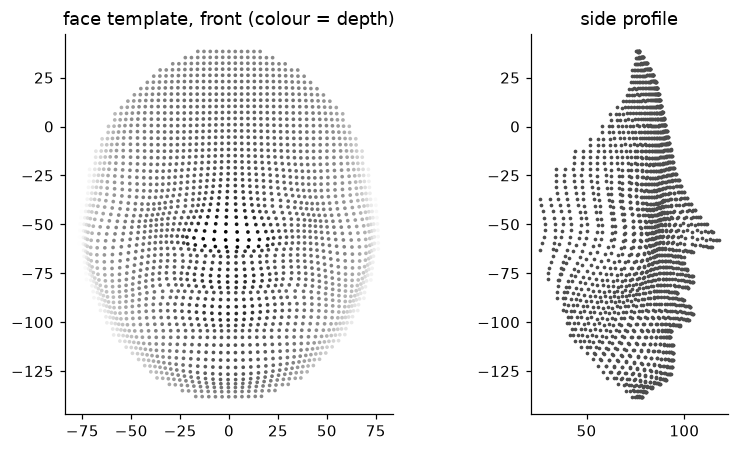

In [4]:
tpl = norm.inverse(model.decoder.template.cpu().numpy())
fig, ax = plt.subplots(1, 2, figsize=(8, 4.2))
ax[0].scatter(tpl[:, 0], tpl[:, 2], s=2, c=tpl[:, 1], cmap='Greys'); ax[0].set_title('face template, front (colour = depth)'); ax[0].set_aspect('equal')
ax[1].scatter(tpl[:, 1], tpl[:, 2], s=2, c='0.3'); ax[1].set_title('side profile'); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()